# Tiền xử lý dữ liệu giao thông theo giờ

Mục tiêu: chuyển CSV gốc thành bảng một dòng cho mỗi giờ quan sát, xuất một CSV tổng cho bước tạo đặc trưng.

Kết quả chính: xem bảng kiểm tra số dòng, ô thiếu và mốc chia sau khi chạy. Các ô thiếu được giữ trong dữ liệu bàn giao để CV học cách điền trên từng fold.

Quyết định: dùng cùng quy tắc làm sạch với năm phương án FE. Đặc trưng A12/B27/C30 được tạo ở bước FE; bộ mã hóa 73 cột của bản cũ được tách khỏi notebook này.

```text
CSV → kiểm tra → gộp target và weather theo giờ → gắn nhãn lễ theo ngày
    → giữ ô thiếu → xuất một CSV tổng
                                  ↓
                FE: chia theo thời gian → CV fit cách điền riêng
```

Notebook được dựng lại từ bản gửi kèm. Phần kiểm tra lặp lại từng hàm được gom thành một lần đối chiếu với `src`; giữ phép che nhiệt độ để giải thích lựa chọn backward-fill. Không huấn luyện mô hình dự đoán lưu lượng tại đây.

## 1. Đọc dữ liệu

Tìm thư mục dự án theo vị trí CSV rồi đọc bằng `keep_default_na=False`. Nhờ vậy chuỗi `"None"` của `holiday` vẫn là nhãn hợp lệ. Chỉ nhập các hàm xử lý dùng chung, không học thống kê tại bước này.

In [1]:
from pathlib import Path

import pandas as pd

# Hỗ trợ chạy từ thư mục gốc dự án hoặc thư mục notebooks/.
cwd = Path.cwd().resolve()
project_dir = next((p for p in (cwd, *cwd.parents) if (p / "data" / "Metro_Interstate_Traffic_Volume.csv").is_file()), None)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy CSV trong thư mục dự án.")

data_path = project_dir / "data" / "Metro_Interstate_Traffic_Volume.csv"

if not data_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy CSV tại {data_path}")

# Giữ nguyên chuỗi "None" như trong notebook validation.
df_raw = pd.read_csv(data_path, keep_default_na=False)
print(f"Số dòng gốc: {len(df_raw):,}")
import sys
import json
import hashlib
import platform
import numpy as np
from IPython.display import Markdown, display
from sklearn.model_selection import TimeSeriesSplit
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))
from src import data as data_tools
from src import preprocessing
from src import data_validation
from src.features import add_time_features, add_weather_features, add_history_features, has_history
SEED = 42

Số dòng gốc: 48,204


### 1.1. Kiểm tra cấu trúc và dữ liệu đầu vào

Kiểm tra tên cột, giá trị số hữu hạn, timestamp đúng đầu giờ và tính nhất quán của target. Nếu có một giờ mang nhiều giá trị lưu lượng, notebook phải dừng để kiểm tra; không tự lấy trung bình hoặc cộng target. `n` là số dòng được kiểm tra.

In [2]:
data_validation.validate_structure_and_time(df_raw)
expected_columns = {'holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all',
                    'weather_main', 'weather_description', 'date_time', 'traffic_volume'}
assert set(df_raw.columns) == expected_columns
for column in ['temp', 'rain_1h', 'snow_1h', 'clouds_all', 'traffic_volume']:
    assert pd.api.types.is_numeric_dtype(df_raw[column]), column
    assert np.isfinite(df_raw[column]).all(), column
assert df_raw.traffic_volume.ge(0).all()
assert df_raw[['rain_1h', 'snow_1h']].ge(0).all().all()
assert df_raw.clouds_all.between(0, 100).all()
display(pd.DataFrame([dict(columns=len(df_raw.columns), actual_NA=int(df_raw.isna().sum().sum()),
                           literal_None_holiday=int(df_raw.holiday.eq('None').sum()), n=len(df_raw))]))

,columns,actual_NA,literal_None_holiday,n
0,9,0,48143,48204


## 2. Tạo bảng mục tiêu theo giờ

Chuyển `date_time` sang kiểu thời gian và kiểm tra từng timestamp có đúng một giá trị `traffic_volume`. Lưu lượng có đơn vị xe/giờ. Dòng dư theo timestamp không đồng nghĩa các bản ghi trùng hoàn toàn vì nhãn thời tiết có thể khác nhau.

In [3]:
# Tạo bảng riêng để kiểm tra, giữ nguyên df_raw.
target_rows = df_raw[["date_time", "traffic_volume"]].copy()
target_rows["date_time"] = pd.to_datetime(
    target_rows["date_time"],
    format="%Y-%m-%d %H:%M:%S",
    errors="raise",
)

# Dừng nếu có mốc thiếu hoặc không nằm đúng đầu giờ.
timestamps = target_rows["date_time"]
if timestamps.isna().any() or not timestamps.eq(timestamps.dt.floor("h")).all():
    raise ValueError("Có timestamp bị thiếu hoặc không nằm đúng đầu giờ.")

# Mỗi giờ phải có đúng một giá trị lưu lượng khác biệt.
target_counts = target_rows.groupby("date_time")["traffic_volume"].nunique()
conflicting_times = target_counts[target_counts.ne(1)]

print(f"Số giờ có mục tiêu không nhất quán: {len(conflicting_times):,}")
if not conflicting_times.empty:
    display(conflicting_times.head())
    raise ValueError("Hãy kiểm tra các giờ trên trước khi gộp.")

Số giờ có mục tiêu không nhất quán: 0


### 2.1. Giữ một target cho mỗi timestamp

Bỏ các cặp thời gian–lưu lượng lặp rồi sắp xếp từ cũ đến mới. CSV gốc vẫn được giữ đủ dòng để gộp thời tiết. Không tạo target bằng 0 ở các giờ không có bản ghi.

In [4]:
# Các cặp timestamp–lưu lượng lặp đã được kiểm tra ở cell trước.
hourly_target = (
    target_rows.drop_duplicates()
    .sort_values("date_time")
    .reset_index(drop=True)
)

print("Kích thước bảng:", hourly_target.shape)
print("Timestamp duy nhất:", hourly_target["date_time"].is_unique)
print("Đã sắp xếp theo thời gian:", hourly_target["date_time"].is_monotonic_increasing)
print(f"Số dòng dư đã bỏ: {len(df_raw) - len(hourly_target):,}")
display(hourly_target.head())

Kích thước bảng: (40575, 2)
Timestamp duy nhất: True
Đã sắp xếp theo thời gian: True
Số dòng dư đã bỏ: 7,629


,date_time,traffic_volume
0,2012-10-02 09:00:00,5545
1,2012-10-02 10:00:00,4516
2,2012-10-02 11:00:00,4767
3,2012-10-02 12:00:00,5026
4,2012-10-02 13:00:00,4918


### 2.2. Kiểm lại số giờ và khoảng trống

Tạo lưới giờ từ mốc đầu đến cuối để đếm giờ không có bản ghi, không chèn các giờ này vào bảng huấn luyện. Đối chiếu các số đã cung cấp; nếu khác thì dừng để xác minh phiên bản dữ liệu. Timestamp chưa có timezone nên chưa xử lý DST.

In [5]:
hour_grid = pd.date_range(hourly_target.date_time.min(), hourly_target.date_time.max(), freq='h')
missing_hours = hour_grid.difference(pd.DatetimeIndex(hourly_target.date_time))
audit_values = dict(raw_rows=len(df_raw), unique_timestamps=len(hourly_target),
                    extra_timestamp_rows=len(df_raw)-len(hourly_target), missing_hours=len(missing_hours))
reference_values = dict(raw_rows=48204, unique_timestamps=40575, extra_timestamp_rows=7629, missing_hours=11976)
audit = pd.DataFrame([dict(item=key, observed=value, reference=reference_values[key],
                           matches=value==reference_values[key], n=len(df_raw))
                      for key,value in audit_values.items()])
display(audit)
assert audit.matches.all(), 'Dữ liệu khác mốc tham chiếu.'
assert hourly_target.date_time.min() == pd.Timestamp('2012-10-02 09:00')
assert hourly_target.date_time.max() == pd.Timestamp('2018-09-30 23:00')

,item,observed,reference,matches,n
0,raw_rows,48204,48204,True,48204
1,unique_timestamps,40575,40575,True,48204
2,extra_timestamp_rows,7629,7629,True,48204
3,missing_hours,11976,11976,True,48204


## 3. Chuẩn hóa thời tiết trước khi gộp

Làm trên bản sao: mask `temp=0 K` và đúng điểm mưa nghi vấn đã nêu trong EDA thành thiếu. Không tự xóa nhiệt độ lặp 276.793 K hoặc coi mọi `rain_1h=0` có nhãn Rain là lỗi. Nhãn thời tiết được bỏ khoảng trắng và chuyển về chữ thường.

In [6]:
weather_numeric_cols = ["temp", "rain_1h", "snow_1h", "clouds_all"]
weather_label_cols = ["weather_main", "weather_description"]

weather_rows = df_raw[weather_numeric_cols + weather_label_cols].copy()

# Dùng lại timestamp đã parse và kiểm tra ở Bước 02.
weather_rows["date_time"] = target_rows["date_time"]

# Đánh dấu hai giá trị đã ghi nhận trong validation trước khi gộp.
# Nếu một giờ không còn giá trị hợp lệ, kết quả của giờ đó sẽ là NaN.
weather_rows["temp"] = weather_rows["temp"].mask(weather_rows["temp"].eq(0))
weather_rows["rain_1h"] = weather_rows["rain_1h"].mask(
    weather_rows["date_time"].eq(pd.Timestamp("2016-07-11 17:00:00"))
    & weather_rows["rain_1h"].eq(9831.3)
)

# Thống nhất khoảng trắng và cách viết hoa của các nhãn thời tiết.
for col in weather_label_cols:
    weather_rows[col] = weather_rows[col].str.strip().str.lower()

### 3.1. Gộp số đo và tập nhãn theo giờ

Với cột số, lấy median trên các giá trị phân biệt trong cùng timestamp; một số đo lặp do nhiều nhãn chỉ được tính một lần. Với cột nhãn, giữ tập nhãn duy nhất, sắp xếp rồi nối bằng ` | `. Hai cách gộp này phải giữ đúng mọi timestamp của bảng mục tiêu.

In [7]:
# Với mỗi cột số, tính median trên các giá trị phân biệt trong cùng giờ.
# Một số đo xuất hiện ở nhiều dòng nhãn chỉ được tính một lần.
hourly_weather_numeric = (
    weather_rows.groupby("date_time")[weather_numeric_cols]
    .agg(lambda values: values.drop_duplicates().median())
)

# Giữ tập nhãn của từng cột, sắp xếp để kết quả tái lập được.
hourly_weather_labels = (
    weather_rows.groupby("date_time")[weather_label_cols]
    .agg(lambda labels: " | ".join(sorted(set(labels) - {""})))
)

hourly_weather = (
    hourly_weather_numeric.join(hourly_weather_labels)
    .reset_index()
)

# Đối chiếu từng timestamp với bảng mục tiêu, kể cả thứ tự.
assert hourly_weather["date_time"].is_unique
assert hourly_weather["date_time"].equals(hourly_target["date_time"])

print("Kích thước bảng thời tiết:", hourly_weather.shape)
print("Timestamp khớp hoàn toàn với bảng mục tiêu")
print("Số giờ còn thiếu theo cột số:")
print(hourly_weather[weather_numeric_cols].isna().sum())

# Xem một giờ đã biết có nhiều nhãn thời tiết trong notebook validation.
display(
    hourly_weather.loc[
        hourly_weather["date_time"].eq(pd.Timestamp("2012-10-10 07:00:00"))
    ]
)

Kích thước bảng thời tiết: (40575, 7)
Timestamp khớp hoàn toàn với bảng mục tiêu
Số giờ còn thiếu theo cột số:
temp          10
rain_1h        1
snow_1h        0
clouds_all     0
dtype: int64


,date_time,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description
178,2012-10-10 07:00:00,281.25,0.0,0.0,99.0,drizzle | rain,light intensity drizzle | light rain


## 4. Ghép target với weather

Ghép theo `date_time` bằng quan hệ một–một. Outer join giúp phát hiện giờ chỉ có ở một phía; chỉ tiếp tục nếu tất cả đều có ở cả hai bảng. Bước này không điền các ô thiếu vừa được đánh dấu.

In [8]:
# Ghép theo timestamp và báo lỗi nếu một bảng có khóa lặp.
hourly_data = hourly_target.merge(
    hourly_weather,
    on="date_time",
    how="outer",
    validate="one_to_one",
    indicator=True,
    sort=True,
)

# Kiểm tra xem có giờ nào chỉ xuất hiện ở một trong hai bảng.
print("Kết quả đối chiếu timestamp:")
print(hourly_data["_merge"].value_counts())

if not hourly_data["_merge"].eq("both").all():
    display(hourly_data.loc[hourly_data["_merge"].ne("both"),
                            ["date_time", "_merge"]].head(10))
    raise ValueError("Hai bảng chưa khớp đủ timestamp.")

# Bỏ cột kiểm tra tạm sau khi xác nhận tất cả timestamp đều khớp.
hourly_data = hourly_data.drop(columns="_merge")

print("Kích thước bảng sau ghép:", hourly_data.shape)
print("Số giờ thiếu nhiệt độ và lượng mưa:")
print(hourly_data[["temp", "rain_1h"]].isna().sum())
display(hourly_data.head())

Kết quả đối chiếu timestamp:
_merge
both          40575
left_only         0
right_only        0
Name: count, dtype: int64
Kích thước bảng sau ghép: (40575, 8)
Số giờ thiếu nhiệt độ và lượng mưa:
temp       10
rain_1h     1
dtype: int64


,date_time,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description
0,2012-10-02 09:00:00,5545,288.28,0.0,0.0,40.0,clouds,scattered clouds
1,2012-10-02 10:00:00,4516,289.36,0.0,0.0,75.0,clouds,broken clouds
2,2012-10-02 11:00:00,4767,289.58,0.0,0.0,90.0,clouds,overcast clouds
3,2012-10-02 12:00:00,5026,290.13,0.0,0.0,90.0,clouds,overcast clouds
4,2012-10-02 13:00:00,4918,291.14,0.0,0.0,75.0,clouds,broken clouds


## 5. Chuẩn hóa nhãn lễ theo ngày

Lấy các nhãn `holiday` khác `"None"`, tạo ánh xạ ngày → tên sự kiện. Nếu một ngày có nhiều tên mâu thuẫn, dừng để xem lại. Chưa bổ sung lịch bên ngoài; không có nhãn trong CSV không bảo đảm ngày đó thực sự không phải ngày lễ.

In [9]:
# Lấy nhãn từ CSV gốc vì hourly_data chưa có cột holiday.
holiday_labels = df_raw["holiday"].str.strip()
has_event_label = holiday_labels.ne("None") & holiday_labels.ne("")

# Chuẩn hóa timestamp về đầu ngày để các giờ cùng ngày có chung khóa.
holiday_by_date = (
    pd.DataFrame({
        "date": target_rows["date_time"].dt.normalize(),
        "holiday_name": holiday_labels,
    })
    .loc[has_event_label]
    .drop_duplicates()
)

# Dừng nếu một ngày còn nhiều tên sau khi bỏ các cặp ngày–tên lặp.
conflicts = holiday_by_date["date"].duplicated(keep=False)
if conflicts.any():
    display(holiday_by_date.loc[conflicts].sort_values("date"))
    raise ValueError("Có ngày mang nhiều tên sự kiện.")

holiday_name_by_date = holiday_by_date.set_index("date")["holiday_name"]
print("Số ngày có nhãn sự kiện:", len(holiday_name_by_date))

Số ngày có nhãn sự kiện: 53


### 5.1. Gắn nhãn cho các giờ cùng ngày

Gán `holiday_name` và `is_holiday` cho mọi giờ đã quan sát trong ngày có nhãn. Đây là bước chuẩn hóa chung được giữ để khớp FE. Các cờ lịch khác và mã sin/cos sẽ tạo riêng trong FE. Ví dụ Labor Day chỉ dùng kiểm tra nhãn, không đánh giá target của test.

In [10]:
# Tạo bảng mới, giữ hourly_data làm bảng đối chiếu của Bước 04.
hourly_with_holiday = hourly_data.copy()
observed_dates = hourly_with_holiday["date_time"].dt.normalize()

# Tra tên theo ngày và tạo cờ 0/1 từ kết quả tra.
event_names = observed_dates.map(holiday_name_by_date)
hourly_with_holiday["holiday_name"] = event_names.fillna("None").astype(object)
hourly_with_holiday["is_holiday"] = event_names.notna().astype("int8")

# Xác nhận phép gắn nhãn giữ nguyên từng timestamp và thứ tự dòng.
assert hourly_with_holiday["date_time"].equals(hourly_data["date_time"])

print("Kích thước bảng:", hourly_with_holiday.shape)
print("Số ngày có ít nhất một giờ được gắn cờ:",
      observed_dates[hourly_with_holiday["is_holiday"].eq(1)].nunique())

# Kiểm tra Labor Day, gồm cả những giờ sau 00:00.
labor_day = hourly_with_holiday.loc[
    observed_dates.eq(pd.Timestamp("2018-09-03")),
    ["date_time", "holiday_name", "is_holiday"],
]
print("Số giờ quan sát trong ngày Labor Day:", len(labor_day))
display(labor_day.head(5))

Kích thước bảng: (40575, 10)
Số ngày có ít nhất một giờ được gắn cờ: 53
Số giờ quan sát trong ngày Labor Day: 24


,date_time,holiday_name,is_holiday
39903,2018-09-03 00:00:00,Labor Day,1
39904,2018-09-03 01:00:00,Labor Day,1
39905,2018-09-03 02:00:00,Labor Day,1
39906,2018-09-03 03:00:00,Labor Day,1
39907,2018-09-03 04:00:00,Labor Day,1


## 6. Chia train, validation, test theo thời gian

Lấy 70% giờ quan sát đầu làm train, 15% tiếp theo làm validation và phần còn lại làm test. Tỷ lệ theo số dòng sau khi gộp, không phải ba khoảng lịch theo tỷ lệ tương ứng. Kiểm tra các tập không chồng timestamp. Chỉ báo metadata và ô thiếu của validation/test; không phân tích quan hệ target hay chấm mô hình trên hai tập này.

In [11]:
# Sắp xếp theo thời gian và kiểm tra mỗi giờ chỉ có một dòng.
ordered_data = hourly_with_holiday.sort_values("date_time").reset_index(drop=True)
timestamps = ordered_data["date_time"]

assert timestamps.notna().all(), "Có timestamp bị thiếu."
assert timestamps.is_unique, "Có timestamp lặp."

# Lấy hai mốc cắt ở 70% và 85% số giờ quan sát, làm tròn xuống.
n_rows = len(ordered_data)
train_end = n_rows * 70 // 100
validation_end = n_rows * 85 // 100

train = ordered_data.iloc[:train_end].copy()
validation = ordered_data.iloc[train_end:validation_end].copy()
test = ordered_data.iloc[validation_end:].copy()

# Kiểm tra đủ dòng và thứ tự thời gian giữa ba tập.
assert all(len(part) > 0 for part in (train, validation, test))
assert len(train) + len(validation) + len(test) == n_rows
assert train["date_time"].max() < validation["date_time"].min()
assert validation["date_time"].max() < test["date_time"].min()

# Tóm tắt mốc chia và vị trí các giá trị thời tiết còn thiếu.
splits = {"train": train, "validation": validation, "test": test}

split_summary = pd.DataFrame(
    {
        "n": len(part),
        "ty_le_pct": round(100 * len(part) / n_rows, 2),
        "tu_gio": part["date_time"].min(),
        "den_gio": part["date_time"].max(),
        "thieu_temp": part["temp"].isna().sum(),
        "thieu_rain_1h": part["rain_1h"].isna().sum(),
    }
    for part in splits.values()
).set_axis(splits.keys(), axis="index")

display(split_summary)

,n,ty_le_pct,tu_gio,den_gio,thieu_temp,thieu_rain_1h
train,28402,70.0,2012-10-02 09:00:00,2017-05-10 04:00:00,10,1
validation,6086,15.0,2017-05-10 05:00:00,2018-01-19 14:00:00,0,0
test,6087,15.0,2018-01-19 15:00:00,2018-09-30 23:00:00,0,0


### 6.1. Đối chiếu với hàm mà FE đang dùng

Dựng lại bảng theo giờ bằng `src.data`, đối chiếu toàn bộ giá trị, tên cột, timestamp và các tập chia với phần làm từng bước phía trên. Đây là kiểm tra để notebook giải thích và code thực nghiệm dùng cùng quy tắc, thay cho nhiều phần kiểm tra lặp trong bản cũ.

In [12]:
raw_parsed = df_raw.copy()
raw_parsed['date_time'] = target_rows['date_time']
canonical_hourly = data_tools.build_hourly_table(raw_parsed, mask_stuck_temp=False, complete_holidays=False)
pd.testing.assert_frame_equal(hourly_with_holiday, canonical_hourly, check_dtype=False)
canonical_splits = preprocessing.split_by_time(canonical_hourly)
for split_name in splits:
    pd.testing.assert_frame_equal(splits[split_name], canonical_splits[split_name], check_dtype=False)
assert pd.concat([part.date_time for part in splits.values()]).is_unique
assert sum(len(part) for part in splits.values()) == len(hourly_target)
display(Markdown(f'Bảng theo giờ và bộ chia khớp code FE: **{len(canonical_hourly):,} giờ**, {len(canonical_hourly.columns)} cột. Các ô thiếu được giữ nguyên.'))

Bảng theo giờ và bộ chia khớp code FE: **40,575 giờ**, 10 cột. Các ô thiếu được giữ nguyên.

## 7. Kiểm chứng lựa chọn điền nhiệt độ trên train

Giữ phép thử trong bản gửi: dùng 80% đầu train học median tháng–giờ, 20% cuối train làm kiểm chứng. Trong mỗi cửa sổ có đủ 7 giờ liên tiếp, giả sử 6 giờ sau bị thiếu rồi so nhiệt độ đầu cửa sổ với median. Các cửa sổ không chồng nhau. Phép thử dùng nhiệt độ, không tối ưu theo target lưu lượng và không dùng validation/test.

In [13]:
# Dùng train trước khi điền để các giá trị được che là quan sát thật.
temp_train = train[["date_time", "temp"]].sort_values("date_time").copy()
cut = len(temp_train) * 80 // 100
reference = temp_train.iloc[:cut].copy()
check = temp_train.iloc[cut:].reset_index(drop=True)

# Chỉ học median từ phần thời gian trước giai đoạn kiểm chứng.
reference["month"] = reference["date_time"].dt.month
reference["hour"] = reference["date_time"].dt.hour
check_medians = reference.groupby(["month", "hour"])["temp"].median()
fallback_median = reference["temp"].median()

assert pd.notna(fallback_median)

records = []

# Các cửa sổ tách rời nhau. Mỗi cửa sổ gồm 1 giờ trước và 6 giờ giả thiếu.
for start in range(0, len(check) - 6, 7):
    window = check.iloc[start:start + 7]

    # Chỉ kiểm chứng nơi có đủ quan sát và đúng 7 giờ liên tiếp.
    if window["temp"].isna().any():
        continue
    if not window["date_time"].diff().iloc[1:].eq(
        pd.Timedelta(hours=1)
    ).all():
        continue

    previous_temp = window.iloc[0]["temp"]

    for horizon in range(1, 7):
        row = window.iloc[horizon]
        timestamp = row["date_time"]
        median_estimate = check_medians.get(
            (timestamp.month, timestamp.hour), float("nan")
        )
        if pd.isna(median_estimate):
            median_estimate = fallback_median

        records.append({
            "date_time": timestamp,
            "cach_quan_sat_truoc_gio": horizon,
            "temp_thuc": row["temp"],
            "temp_giu_quan_sat_truoc": previous_temp,
            "temp_median_thang_gio": median_estimate,
        })

comparison = pd.DataFrame(records)
assert not comparison.empty, "Không tìm được cửa sổ đủ điều kiện."

print("Giai đoạn kiểm chứng:",
      check["date_time"].min(), "đến", check["date_time"].max())
print("Số cửa sổ hợp lệ:", len(comparison) // 6)
print("Số giờ được kiểm chứng:", len(comparison))

Giai đoạn kiểm chứng: 2016-09-12 12:00:00 đến 2017-05-10 04:00:00
Số cửa sổ hợp lệ: 776
Số giờ được kiểm chứng: 4656


### 7.1. Đo sai số khôi phục nhiệt độ

Tính MAE theo khoảng cách 1–6 giờ trên toàn bộ cửa sổ hợp lệ, đồng thời xem riêng 06:00–09:00. MAE có đơn vị K; đây là sai số điền nhiệt độ, không phải MAE dự đoán lưu lượng. Kết quả chỉ hỗ trợ trên các cửa sổ đầy đủ đã chọn, chưa xác minh nhiệt độ thật ở những giờ bị thiếu hoặc ngưỡng 6 giờ tối ưu.

In [14]:
# Sai số tuyệt đối tính theo Kelvin.
comparison["sai_so_giu_truoc_K"] = (
    comparison["temp_giu_quan_sat_truoc"] - comparison["temp_thuc"]
).abs()
comparison["sai_so_median_K"] = (
    comparison["temp_median_thang_gio"] - comparison["temp_thuc"]
).abs()

# MAE là trung bình sai số tuyệt đối. Giá trị nhỏ hơn là tốt hơn.
by_horizon = comparison.groupby("cach_quan_sat_truoc_gio").agg(
    n=("temp_thuc", "size"),
    MAE_giu_truoc_K=("sai_so_giu_truoc_K", "mean"),
    MAE_median_K=("sai_so_median_K", "mean"),
)

morning = comparison.loc[comparison["date_time"].dt.hour.between(6, 9)]
morning_by_horizon = morning.groupby("cach_quan_sat_truoc_gio").agg(
    n=("temp_thuc", "size"),
    MAE_giu_truoc_K=("sai_so_giu_truoc_K", "mean"),
    MAE_median_K=("sai_so_median_K", "mean"),
)

print("Toàn bộ các giờ kiểm chứng:")
display(by_horizon.round(3))

print("Riêng các giờ 06:00–09:00:")
display(morning_by_horizon.round(3))

Toàn bộ các giờ kiểm chứng:
Riêng các giờ 06:00–09:00:


,n,MAE_giu_truoc_K,MAE_median_K
cach_quan_sat_truoc_gio,,,
1,776,0.638,5.843
2,776,1.261,5.833
3,776,1.859,5.864
4,776,2.402,5.883
5,776,2.913,5.862
6,776,3.335,5.855


,n,MAE_giu_truoc_K,MAE_median_K
cach_quan_sat_truoc_gio,,,
1,122,0.493,5.820
2,125,0.874,5.574
3,124,1.367,6.036
4,125,1.494,5.806
5,127,1.788,5.609
6,135,1.967,5.715


### 7.2. So sánh hai đường sai số

Biểu đồ cho biết lỗi khôi phục thay đổi theo độ dài đoạn thiếu; mỗi điểm dùng số mẫu `n` trong bảng trước. Đọc biểu đồ như sau: đường thấp hơn có MAE nhiệt độ thấp hơn trên tập cửa sổ tương ứng. Đường tăng theo độ dài thiếu cho thấy việc giữ quan sát cũ giảm độ chính xác theo thời gian.

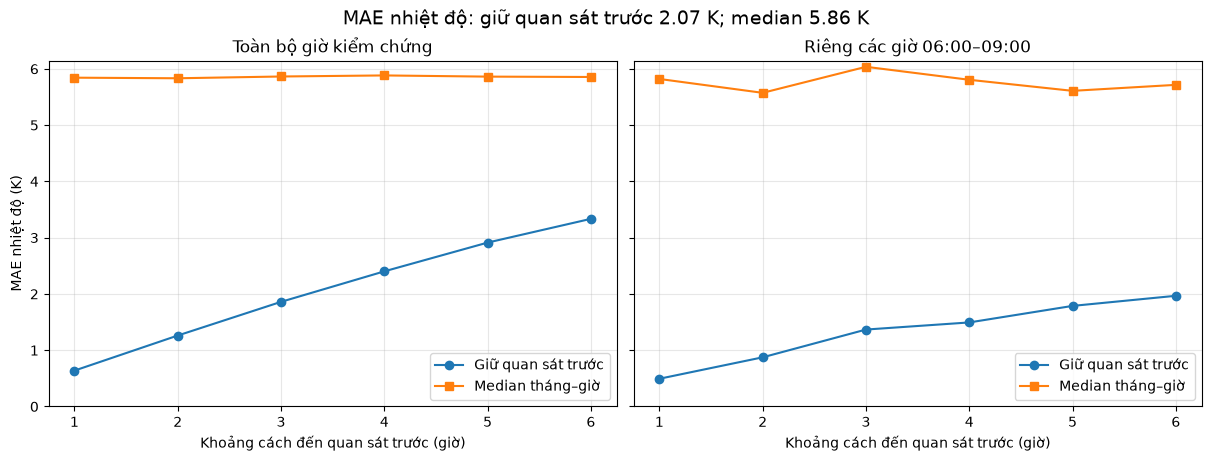

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.5),
    sharex=True,
    sharey=True,
    layout="constrained",
)

plot_tables = [
    (by_horizon, "Toàn bộ giờ kiểm chứng"),
    (morning_by_horizon, "Riêng các giờ 06:00–09:00"),
]

for ax, (table, title) in zip(axes, plot_tables):
    ax.plot(
        table.index,
        table["MAE_giu_truoc_K"],
        marker="o",
        label="Giữ quan sát trước",
    )
    ax.plot(
        table.index,
        table["MAE_median_K"],
        marker="s",
        label="Median tháng–giờ",
    )

    ax.set_title(title)
    ax.set_xlabel("Khoảng cách đến quan sát trước (giờ)")
    ax.set_xticks(range(1, 7))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("MAE nhiệt độ (K)")
fig.suptitle(f"MAE nhiệt độ: giữ quan sát trước {comparison.sai_so_giu_truoc_K.mean():.2f} K; median {comparison.sai_so_median_K.mean():.2f} K", fontsize=14)

figures_dir = project_dir / 'figures'
figures_dir.mkdir(exist_ok=True)
fig.savefig(figures_dir / 'preprocessing_01_temperature_fill.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## 8. Điền thiếu đúng phạm vi một fold CV

Rò rỉ dữ liệu xảy ra khi bước học nhận thông tin từ phần dùng để chấm. Vì vậy không dùng median học toàn train trước khi chạy CV trên train. Minh họa dưới đây lấy đúng cohort đủ history và fold đầu giống FE; các đặc trưng history chỉ dùng tạm để xác định cùng tập giờ. Chỉ những dòng fold-train được học median. Các quan sát weather gốc ngoài cohort vẫn được giữ làm ngữ cảnh tra quá khứ.

In [16]:
featured_train = add_history_features(add_weather_features(add_time_features(train)))
common_cohort = featured_train.loc[has_history(featured_train)].reset_index(drop=True)
fit_index, score_index = next(TimeSeriesSplit(n_splits=3).split(common_cohort))
fit_times = common_cohort.iloc[fit_index].date_time
score_times = common_cohort.iloc[score_index].date_time
fold_train = train.set_index('date_time', drop=False).loc[fit_times].reset_index(drop=True)
fold_statistics = preprocessing.fit_weather_fill(fold_train)
display(pd.DataFrame([dict(fit_start=fit_times.min(), fit_end=fit_times.max(),
    score_start=score_times.min(), score_end=score_times.max(), n_fit=len(fit_times), n=len(score_times),
    temp_median_K=fold_statistics['temp_fallback'], rain_median_mm=fold_statistics['rain_median'])]))
assert fit_times.max() < score_times.min()

,fit_start,fit_end,score_start,score_end,n_fit,n,temp_median_K,rain_median_mm
0,2012-10-09 09:00:00,2013-08-05 19:00:00,2013-08-05 20:00:00,2015-07-12 06:00:00,5628,5625,277.38,0.0


### 8.1. Áp dụng quy tắc đã học, chỉ thay ô thiếu

Nhiệt độ thiếu ưu tiên quan sát gốc nằm trước đó tối đa 6 giờ, sau đó median tháng–giờ và median toàn fold-train. Mưa thiếu dùng median fold-train. Không lấy nhiệt độ đã điền làm quan sát mới, không dùng quan sát tương lai. Các bảng đã điền dưới đây chỉ minh họa một fold, không phải CSV đầu vào cho toàn bộ CV.

In [17]:
fit_context = train.loc[train.date_time.le(fit_times.max())].copy()
score_context = train.loc[train.date_time.gt(fit_times.max()) & train.date_time.le(score_times.max())].copy()
filled_fit_context = preprocessing.fill_weather(fit_context, fold_statistics)
filled_score_context = preprocessing.fill_weather(score_context, fold_statistics, history=fit_context)
fill_rows = []
for name, original_part, filled_part in [('fold-train context', fit_context, filled_fit_context),
                                        ('fold-score context', score_context, filled_score_context)]:
    pd.testing.assert_frame_equal(original_part.drop(columns=['temp','rain_1h']),
                                  filled_part.drop(columns=['temp','rain_1h']))
    for column in ['temp', 'rain_1h']:
        observed = original_part[column].notna()
        pd.testing.assert_series_equal(original_part.loc[observed,column], filled_part.loc[observed,column])
        assert filled_part[column].notna().all()
        fill_rows.append(dict(scope=name, column=column, missing_before=int((~observed).sum()),
                              missing_after=int(filled_part[column].isna().sum()), n=len(original_part)))
display(pd.DataFrame(fill_rows))
missing_examples = score_context.loc[score_context.temp.isna(), ['date_time','temp']].copy()
missing_examples['filled_temp_K'] = filled_score_context.loc[score_context.temp.isna(),'temp']
missing_examples['n'] = 1
display(missing_examples)

,scope,column,missing_before,missing_after,n
0,fold-train context,temp,0,0,6824
1,fold-train context,rain_1h,0,0,6824
2,fold-score context,temp,10,0,7493
3,fold-score context,rain_1h,0,0,7493


,date_time,temp,filled_temp_K,n
10079,2014-01-31 03:00:00,NaN,255.93,1
10080,2014-01-31 04:00:00,NaN,255.93,1
10081,2014-01-31 05:00:00,NaN,255.93,1
10082,2014-01-31 06:00:00,NaN,255.93,1
10127,2014-02-02 03:00:00,NaN,255.37,1
10128,2014-02-02 04:00:00,NaN,255.37,1
10129,2014-02-02 05:00:00,NaN,255.37,1
10130,2014-02-02 06:00:00,NaN,255.37,1
10131,2014-02-02 07:00:00,NaN,255.37,1
10132,2014-02-02 08:00:00,NaN,255.37,1


### 8.2. Kiểm tra ranh giới 6 giờ và loại thông tin tương lai

Tạo ví dụ nhỏ: 00h có nhiệt độ thật, 06h và 07h thiếu, 08h có quan sát tương lai. 06h phải dùng 00h; 07h phải dùng median vì quan sát 00h đã quá 6 giờ. Thay nhiệt độ 08h không được làm thay đổi kết quả ở 06h hoặc 07h.

In [18]:
# 00h có nhiệt độ thật. 06h và 07h thiếu. 08h có quan sát tương lai.
example = pd.DataFrame({
    "date_time": pd.to_datetime(["2014-01-01 00:00", "2014-01-01 06:00",
                                "2014-01-01 07:00", "2014-01-01 08:00"]),
    "temp": [250.0, float("nan"), float("nan"), 310.0],
    "rain_1h": [0.0] * 4,
})
stats = {"temp_by_month_hour": pd.Series([270.0], index=pd.MultiIndex.from_tuples([(1, 7)])),
         "temp_fallback": 280.0, "rain_median": 0.0}
result = preprocessing.fill_weather(example.iloc[1:], stats, history=example.iloc[:1])
assert result["temp"].tolist() == [250.0, 270.0, 310.0]
fallback = preprocessing.fill_weather(example.iloc[2:3], {**stats, "temp_by_month_hour":
                                      stats["temp_by_month_hour"].iloc[:0]}, history=example.iloc[:1])
assert fallback["temp"].item() == 280.0
print("6 giờ: dùng quan sát thật. 7 giờ: dùng median nhóm hoặc median toàn train.")
altered_example = example.copy()
altered_example.loc[altered_example.date_time.eq(pd.Timestamp('2014-01-01 08:00')), 'temp'] = 999.
altered_result = preprocessing.fill_weather(altered_example.iloc[1:], stats, history=altered_example.iloc[:1])
np.testing.assert_allclose(result.temp.iloc[:2], altered_result.temp.iloc[:2])
display(Markdown('Kiểm tra biên 6 giờ, median dự phòng và can thiệp quan sát tương lai đều qua.'))

6 giờ: dùng quan sát thật. 7 giờ: dùng median nhóm hoặc median toàn train.


Kiểm tra biên 6 giờ, median dự phòng và can thiệp quan sát tương lai đều qua.

## 9. Xuất một CSV tổng cho FE

Giữ nguyên phương pháp làm sạch và xuất duy nhất `data/preprocessed/hourly_unfilled.csv`. File có một dòng cho mỗi giờ quan sát, chứa target, thời tiết và nhãn lễ theo ngày. Không xuất riêng train/validation/test. Những tập đã tạo ở mục 6 chỉ dùng trong bộ nhớ để giải thích ranh giới và kiểm chứng quy tắc.

FE đọc chính CSV này, tạo các cấu hình rồi chia dữ liệu theo thời gian. Các ô thiếu được giữ để pipeline học cách điền trong từng fold. Thông tin truy vết được lưu ở `notebooks/preprocessing/outputs/preprocessing_manifest.json`, tách khỏi thư mục dữ liệu.

In [19]:
output_dir = project_dir / 'data/preprocessed'
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / 'hourly_unfilled.csv'
hourly_with_holiday.to_csv(output_path, index=False)
metadata_dir = project_dir / 'notebooks/preprocessing/outputs'
metadata_dir.mkdir(parents=True, exist_ok=True)
metadata = dict(source=data_path.name, source_sha256=hashlib.sha256(data_path.read_bytes()).hexdigest(),
    output='data/preprocessed/hourly_unfilled.csv', output_sha256=hashlib.sha256(output_path.read_bytes()).hexdigest(),
    n_raw=len(df_raw), n_hourly=len(hourly_with_holiday), missing_hours=len(missing_hours),
    columns=hourly_with_holiday.columns.tolist(), imputation_fitted=False,
    rules=dict(keep_default_na=False, hourly_numeric='median distinct values', hourly_labels='sorted union',
               mask_temp_zero=True, mask_known_rain_outlier=True, mask_stuck_temp=False,
               complete_holidays=False, target_fill=False, split='performed in memory by FE; 70/15/15 chronological',
               DST='not analysed', median_scope='fit only on each fold-train'),
    code_sha256={name:hashlib.sha256((project_dir/'src'/name).read_bytes()).hexdigest()
                 for name in ['data.py','preprocessing.py','features.py','data_validation.py']},
    versions=dict(python=platform.python_version(), pandas=pd.__version__, numpy=np.__version__))
(metadata_dir / 'preprocessing_manifest.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
display(pd.DataFrame([dict(file=output_path.name, n=len(hourly_with_holiday), n_columns=len(hourly_with_holiday.columns),
                           missing_temp=int(hourly_with_holiday.temp.isna().sum()),
                           missing_rain=int(hourly_with_holiday.rain_1h.isna().sum()))]))

,file,n,n_columns,missing_temp,missing_rain
0,hourly_unfilled.csv,40575,10,10,1


### 9.1. Đọc lại CSV tổng và kiểm tra bàn giao

Đọc đúng dtype số và chỉ xem chuỗi rỗng ở cột số là thiếu; chuỗi `None` của tên lễ vẫn được giữ. Đối chiếu toàn bộ file với bảng trước khi xuất và với hàm làm sạch dùng chung. CSV này còn ô thiếu có chủ đích. Việc chia train/validation/test và fit median sẽ được thực hiện khi chạy FE/CV.

In [20]:
numeric_dtypes = hourly_with_holiday.select_dtypes(include='number').dtypes.to_dict()
loaded_hourly = pd.read_csv(output_path, keep_default_na=False,
                           dtype=numeric_dtypes, na_values={column:[''] for column in numeric_dtypes},
                           float_precision='round_trip')
loaded_hourly['date_time'] = pd.to_datetime(loaded_hourly.date_time, format='%Y-%m-%d %H:%M:%S', errors='raise')
pd.testing.assert_frame_equal(loaded_hourly, hourly_with_holiday, check_dtype=False, check_exact=True)
pd.testing.assert_frame_equal(loaded_hourly, canonical_hourly, check_dtype=False, check_exact=True)
assert loaded_hourly.date_time.is_unique and loaded_hourly.date_time.is_monotonic_increasing
assert loaded_hourly.traffic_volume.notna().all()
display(Markdown(f'Đã xuất và đọc lại đúng **{len(loaded_hourly):,} giờ** trong một CSV tổng. Target, thứ tự thời gian và các ô thiếu được giữ nguyên.'))

Đã xuất và đọc lại đúng **40,575 giờ** trong một CSV tổng. Target, thứ tự thời gian và các ô thiếu được giữ nguyên.

## 10. Tổng kết

Giữ một target cho mỗi giờ quan sát, gộp weather theo giá trị phân biệt và tập nhãn, đánh dấu các điểm bất thường đã thống nhất rồi xuất một CSV tổng. FE chia theo thời gian trong bộ nhớ. Bảng bàn giao giữ thiếu; cách điền chỉ học trong phạm vi mỗi lần huấn luyện.

Phép che nhiệt độ hỗ trợ quy tắc ưu tiên quan sát trước tối đa 6 giờ trên các cửa sổ train đã thử. Đây chưa phải chứng minh 6 giờ là ngưỡng tối ưu hoặc nhiệt độ thật của các giờ thiếu.

Bước tiếp theo là tạo và đối chứng A12, numeric16, labels23, B27, C30. Nhãn lễ theo CSV có thể chưa đủ; timestamp chưa xử lý DST; weather cùng giờ chỉ dùng khi sẵn có tại thời điểm dự đoán.